# Machine Learning Assignment 5: Clustering

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Dataset
from sklearn.datasets import load_iris

# Feature scaling
from sklearn.preprocessing import StandardScaler

# KMeans clustering
from sklearn.cluster import KMeans

# Hierarchical clustering
from sklearn.cluster import AgglomerativeClustering

# Dendrogram
from scipy.cluster.hierarchy import dendrogram, linkage

# Graphs
import matplotlib.pyplot as plt
import seaborn as sns

# Graph style
sns.set_style("whitegrid")

In [2]:
# Load the Iris dataset
iris = load_iris()

# Create a DataFrame containing the four measurements
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the species names temporarily
df["species"] = [
    iris.target_names[value]
    for value in iris.target
]

# Display the first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nSpecies distribution:")
print(df["species"].value_counts())

Dataset shape: (150, 5)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species               object
dtype: object

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate rows:
1

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Removing the Species Column

In [4]:
# Remove the species column
X = df.drop("species", axis=1)

print("Shape after removing species:", X.shape)

X.head()

Shape after removing species: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## Feature Scaling

In [5]:
# Create the StandardScaler
scaler = StandardScaler()

# Standardize the four numerical features
X_scaled = scaler.fit_transform(X)

print("Feature scaling completed.")
print("Scaled data shape:", X_scaled.shape)

Feature scaling completed.
Scaled data shape: (150, 4)


## 2. KMeans Clustering


### Selecting the Number of Clusters

In [6]:
# Store the inertia for each value of k
inertia_values = []

# Test cluster counts from 1 to 10
k_values = range(1, 11)

for k in k_values:

    # Create and train a KMeans model
    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans_test.fit(X_scaled)

    # Store the inertia
    inertia_values.append(kmeans_test.inertia_)

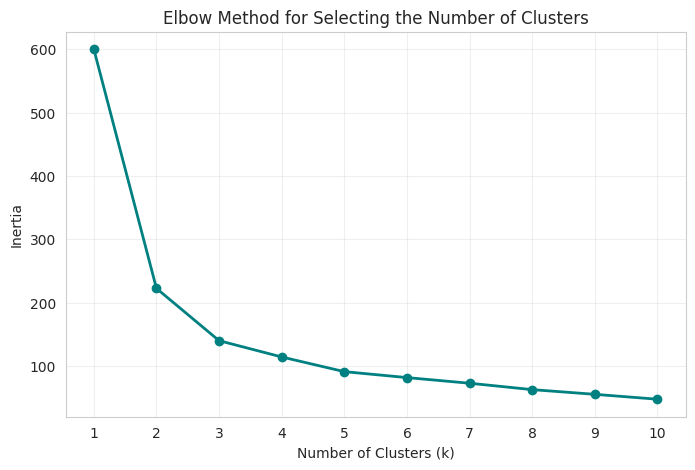

In [7]:
# Create the Elbow Method graph
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o",
    color="teal",
    linewidth=2
)

plt.title("Elbow Method for Selecting the Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

### Applying KMeans

In [8]:
# Create the final KMeans model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train the model and assign every flower to a cluster
kmeans_labels = kmeans.fit_predict(X_scaled)

# Add the cluster labels to the DataFrame
df["KMeans Cluster"] = kmeans_labels

print("KMeans clustering completed.")

print("\nNumber of flowers in each cluster:")
print(df["KMeans Cluster"].value_counts().sort_index())

df.head()

KMeans clustering completed.

Number of flowers in each cluster:
KMeans Cluster
0    53
1    50
2    47
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,KMeans Cluster
0,5.1,3.5,1.4,0.2,setosa,1
1,4.9,3.0,1.4,0.2,setosa,1
2,4.7,3.2,1.3,0.2,setosa,1
3,4.6,3.1,1.5,0.2,setosa,1
4,5.0,3.6,1.4,0.2,setosa,1


In [9]:
# Convert the scaled centroids back to the original measurement units
centroids_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

# Convert centroids into a DataFrame
centroids_df = pd.DataFrame(
    centroids_original,
    columns=X.columns
)

centroids_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.801887,2.673585,4.369811,1.413208
1,5.006000,3.428000,1.462000,0.246000
2,6.780851,3.095745,5.510638,1.972340


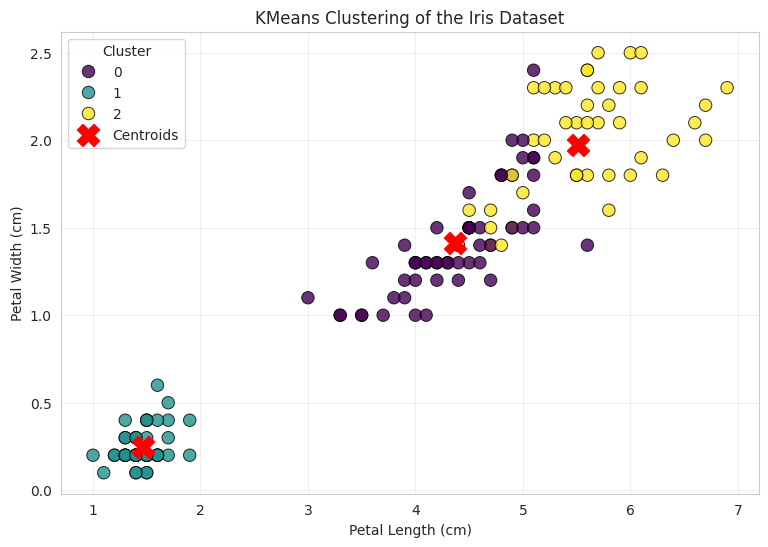

In [10]:
# Create the KMeans cluster visualization
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="KMeans Cluster",
    palette="viridis",
    s=80,
    edgecolor="black",
    alpha=0.8
)

# Add the cluster centroids
plt.scatter(
    centroids_df["petal length (cm)"],
    centroids_df["petal width (cm)"],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.title("KMeans Clustering of the Iris Dataset")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.show()

### KMeans Cluster Interpretation

## 3. Hierarchical Clustering

### Dendrogram

In [11]:
# Calculate the hierarchical linkage matrix
linkage_matrix = linkage(
    X_scaled,
    method="ward"
)

print("Linkage matrix shape:", linkage_matrix.shape)

Linkage matrix shape: (149, 4)


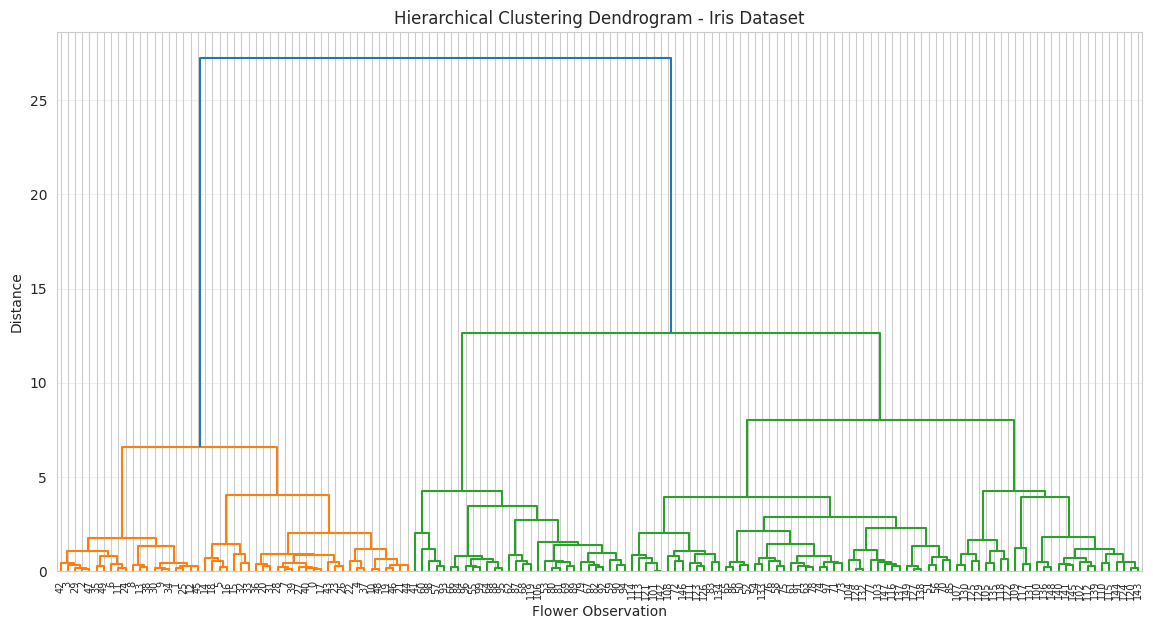

In [12]:
# Create the hierarchical clustering dendrogram
plt.figure(figsize=(14, 7))

dendrogram(
    linkage_matrix,
    leaf_rotation=90,
    leaf_font_size=7
)

plt.title("Hierarchical Clustering Dendrogram - Iris Dataset")
plt.xlabel("Flower Observation")
plt.ylabel("Distance")
plt.grid(axis="y", alpha=0.3)
plt.show()

### Dendrogram Interpretation

### Applying Agglomerative Hierarchical Clustering


In [13]:
# Create the hierarchical clustering model
hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

# Assign every flower to a hierarchical cluster
hierarchical_labels = hierarchical_model.fit_predict(
    X_scaled
)

# Add the labels to the DataFrame
df["Hierarchical Cluster"] = hierarchical_labels

print("Hierarchical clustering completed.")

print("\nNumber of flowers in each cluster:")
print(
    df["Hierarchical Cluster"]
    .value_counts()
    .sort_index()
)

df.head()


Hierarchical clustering completed.

Number of flowers in each cluster:
Hierarchical Cluster
0    71
1    49
2    30
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,KMeans Cluster,Hierarchical Cluster
0,5.1,3.5,1.4,0.2,setosa,1,1
1,4.9,3.0,1.4,0.2,setosa,1,1
2,4.7,3.2,1.3,0.2,setosa,1,1
3,4.6,3.1,1.5,0.2,setosa,1,1
4,5.0,3.6,1.4,0.2,setosa,1,1


Visualize the hierarchical clusters

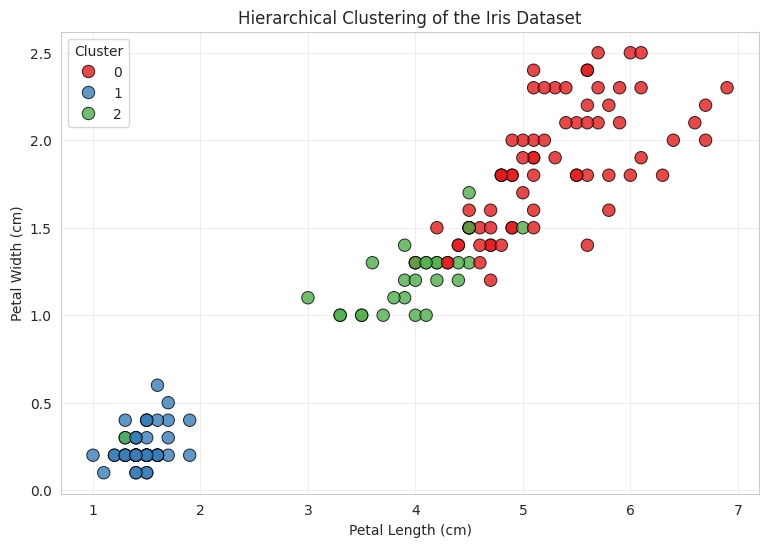

In [14]:
# Create the hierarchical clustering visualization
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="Hierarchical Cluster",
    palette="Set1",
    s=80,
    edgecolor="black",
    alpha=0.8
)

plt.title("Hierarchical Clustering of the Iris Dataset")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.show()

### Hierarchical Cluster Interpretation

In [15]:
# Compare the cluster sizes produced by both algorithms
cluster_size_comparison = pd.DataFrame({
    "KMeans Cluster Size": (
        df["KMeans Cluster"]
        .value_counts()
        .sort_index()
    ),
    "Hierarchical Cluster Size": (
        df["Hierarchical Cluster"]
        .value_counts()
        .sort_index()
    )
})

cluster_size_comparison

,KMeans Cluster Size,Hierarchical Cluster Size
0,53,71
1,50,49
2,47,30


## Comparison of KMeans and Hierarchical Clustering

Both algorithms created three clusters from the four flower measurements.

KMeans forms clusters around centroids and attempts to minimize the distance
between observations and their assigned centroid. It is simple, efficient
and suitable for compact numerical groups.

Hierarchical clustering builds a tree of relationships by repeatedly merging
similar observations and clusters. Its dendrogram helps visualize the
hierarchical structure of the dataset.

Both methods clearly separated the flowers with the smallest petal
measurements. The other flower groups showed some overlap because their
measurements are more similar.

## Conclusion

This project applied KMeans and hierarchical clustering to the Iris dataset.

The preprocessing process included:

- Loading the Iris dataset from scikit-learn
- Converting the data into a pandas DataFrame
- Inspecting the dataset
- Removing the species column
- Standardizing the four numerical features

This demonstrates that clustering algorithms can discover natural patterns
without using the known species labels.